# Проверка качества данных: supermarket sales

Источник данных: `Creation Queries.sql` из набора supermarket-sales. Ноутбук загружает данные из SQL-файла, формирует `pandas.DataFrame` и выполняет технические проверки качества данных: профиль полей, null/not null, distinct, длины строк, описательные статистики, PSI, стандартное отклонение, корреляции, top-X значений и гистограммы.

In [1]:
import os
os.environ.setdefault('MPLCONFIGDIR', './.matplotlib')

import ast
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 140)
plt.style.use('seaborn-v0_8-whitegrid')

## 1. Загрузка данных из SQL

In [2]:
sql_path = Path('Creation Queries.sql')
sql_text = sql_path.read_text(encoding='utf-8')

columns = re.findall(r'`([^`]+)`\s+(?:INT|VARCHAR|NUMERIC)', sql_text.split(');', 1)[0])
insert_part = re.search(r'INSERT\s+INTO\s+`sales`\s+VALUES\s*(.*);', sql_text, flags=re.S | re.I).group(1)
rows = [ast.literal_eval(match.group(0)) for match in re.finditer(r'\([^()]+\)', insert_part)]

df = pd.DataFrame(rows, columns=columns)

numeric_cols = ['sale_id', 'unit_price', 'quantity', 'tax', 'total_price', 'reward_points']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

object_cols = df.select_dtypes(include='object').columns.tolist()
measure_cols = ['unit_price', 'quantity', 'tax', 'total_price', 'reward_points']

print(f'Размер набора данных: {df.shape[0]} строк x {df.shape[1]} столбцов')
display(df.head())
display(df.dtypes.to_frame('dtype'))

Размер набора данных: 1000 строк x 12 столбцов


,sale_id,branch,city,customer_type,gender,product_name,product_category,unit_price,quantity,tax,total_price,reward_points
0,1,A,New York,Member,Male,Shampoo,Personal Care,5.50,3,1.16,17.66,1
1,2,B,Los Angeles,Normal,Female,Notebook,Stationery,2.75,10,1.93,29.43,0
2,3,A,New York,Member,Female,Apple,Fruits,1.20,15,1.26,19.26,1
3,4,A,Chicago,Normal,Male,Detergent,Household,7.80,5,2.73,41.73,0
4,5,B,Los Angeles,Member,Female,Orange Juice,Beverages,3.50,7,1.72,26.22,2


,dtype
sale_id,int64
branch,object
city,object
customer_type,object
gender,object
product_name,object
product_category,object
unit_price,float64
quantity,int64
tax,float64


## 2. Профилирование: Count, Count distinct, Null / Not null

In [3]:
profile = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'count': df.count(),
    'count_distinct': df.nunique(dropna=True),
    'count_null': df.isna().sum(),
    'count_not_null': df.notna().sum(),
    'null_pct': (df.isna().mean() * 100).round(2),
})
profile['duplicate_column_values_pct'] = ((1 - profile['count_distinct'] / profile['count_not_null']) * 100).round(2)
display(profile)

,dtype,count,count_distinct,count_null,count_not_null,null_pct,duplicate_column_values_pct
sale_id,int64,1000,1000,0,1000,0.0,0.0
branch,object,1000,2,0,1000,0.0,99.8
city,object,1000,3,0,1000,0.0,99.7
customer_type,object,1000,2,0,1000,0.0,99.8
gender,object,1000,2,0,1000,0.0,99.8
product_name,object,1000,5,0,1000,0.0,99.5
product_category,object,1000,5,0,1000,0.0,99.5
unit_price,float64,1000,787,0,1000,0.0,21.3
quantity,int64,1000,20,0,1000,0.0,98.0
tax,float64,1000,755,0,1000,0.0,24.5


## 3. Длины строк: Length Max / Min / Avg

In [4]:
length_profile = pd.DataFrame(index=object_cols)
for col in object_cols:
    lengths = df[col].dropna().astype(str).str.len()
    length_profile.loc[col, 'length_min'] = lengths.min()
    length_profile.loc[col, 'length_max'] = lengths.max()
    length_profile.loc[col, 'length_avg'] = lengths.mean()
    length_profile.loc[col, 'length_median'] = lengths.median()

length_profile = length_profile.round(2)
display(length_profile)

,length_min,length_max,length_avg,length_median
branch,1.0,1.0,1.00,1.0
city,7.0,11.0,8.65,8.0
customer_type,6.0,6.0,6.00,6.0
gender,4.0,6.0,4.94,4.0
product_name,5.0,12.0,8.24,8.0
product_category,6.0,13.0,9.40,9.0


## 4. Числовые статистики: Max / Min / Avg / Median / Mean / Percentile / Stddev

In [5]:
percentiles = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
num_stats = df[measure_cols].describe(percentiles=percentiles).T
num_stats = num_stats.rename(columns={'50%': 'median', 'mean': 'mean_avg', 'std': 'stddev'})
num_stats = num_stats[['count', 'min', 'max', 'mean_avg', 'median', 'stddev', '1%', '5%', '25%', '75%', '95%', '99%']]
display(num_stats.round(3))

,count,min,max,mean_avg,median,stddev,1%,5%,25%,75%,95%,99%
unit_price,1000.0,1.02,20.98,10.836,10.615,5.776,1.13,1.920,5.868,15.882,19.962,20.810
quantity,1000.0,1.00,20.00,10.337,10.000,6.030,1.00,1.000,5.000,16.000,20.000,20.000
tax,1000.0,0.08,28.39,7.758,5.870,6.538,0.21,0.680,2.510,11.522,20.935,26.310
total_price,1000.0,1.21,433.99,118.584,89.705,99.936,3.23,10.438,38.380,176.072,320.072,402.118
reward_points,1000.0,0.00,43.00,6.057,0.000,9.350,0.00,0.000,0.000,10.000,28.000,37.000


## 5. PSI (Population Stability Index)

Для демонстрации стабильности распределений данные разделены на две выборки по `sale_id`: первая половина используется как baseline, вторая — как comparison. Обычно PSI считают между периодами, версиями источника или train/test выборками.

In [6]:
baseline = df[df['sale_id'] <= df['sale_id'].median()].copy()
comparison = df[df['sale_id'] > df['sale_id'].median()].copy()

def psi_from_distributions(base_counts, comp_counts, eps=1e-6):
    all_index = base_counts.index.union(comp_counts.index)
    base_pct = (base_counts.reindex(all_index, fill_value=0) / max(base_counts.sum(), 1)).clip(lower=eps)
    comp_pct = (comp_counts.reindex(all_index, fill_value=0) / max(comp_counts.sum(), 1)).clip(lower=eps)
    return float(((comp_pct - base_pct) * np.log(comp_pct / base_pct)).sum())

def psi_numeric(base, comp, bins=10):
    base_non_null = base.dropna()
    comp_non_null = comp.dropna()
    if base_non_null.nunique() <= 1 or comp_non_null.empty:
        return np.nan
    _, bin_edges = pd.qcut(base_non_null, q=min(bins, base_non_null.nunique()), retbins=True, duplicates='drop')
    bin_edges[0] = -np.inf
    bin_edges[-1] = np.inf
    base_bins = pd.cut(base_non_null, bins=bin_edges, include_lowest=True)
    comp_bins = pd.cut(comp_non_null, bins=bin_edges, include_lowest=True)
    return psi_from_distributions(base_bins.value_counts(sort=False), comp_bins.value_counts(sort=False))

def psi_categorical(base, comp):
    return psi_from_distributions(base.value_counts(dropna=False), comp.value_counts(dropna=False))

psi_rows = []
for col in df.columns:
    if col == 'sale_id':
        continue
    if col in measure_cols:
        value = psi_numeric(baseline[col], comparison[col])
    else:
        value = psi_categorical(baseline[col], comparison[col])
    psi_rows.append({'column': col, 'psi': value})

psi = pd.DataFrame(psi_rows).sort_values('psi', ascending=False)
psi['interpretation'] = pd.cut(
    psi['psi'],
    bins=[-np.inf, 0.1, 0.25, np.inf],
    labels=['stable / no significant shift', 'moderate shift', 'significant shift']
)
display(psi.round(4))

,column,psi,interpretation
7,quantity,0.0436,stable / no significant shift
1,city,0.0336,stable / no significant shift
0,branch,0.0264,stable / no significant shift
5,product_category,0.0250,stable / no significant shift
6,unit_price,0.0196,stable / no significant shift
8,tax,0.0170,stable / no significant shift
9,total_price,0.0154,stable / no significant shift
4,product_name,0.0067,stable / no significant shift
10,reward_points,0.0029,stable / no significant shift
3,gender,0.0001,stable / no significant shift


## 6. Корреляционная матрица

,unit_price,quantity,tax,total_price,reward_points
unit_price,1.000,-0.034,0.602,0.602,0.362
quantity,-0.034,1.000,0.684,0.684,0.398
tax,0.602,0.684,1.000,1.000,0.591
total_price,0.602,0.684,1.000,1.000,0.591
reward_points,0.362,0.398,0.591,0.591,1.000


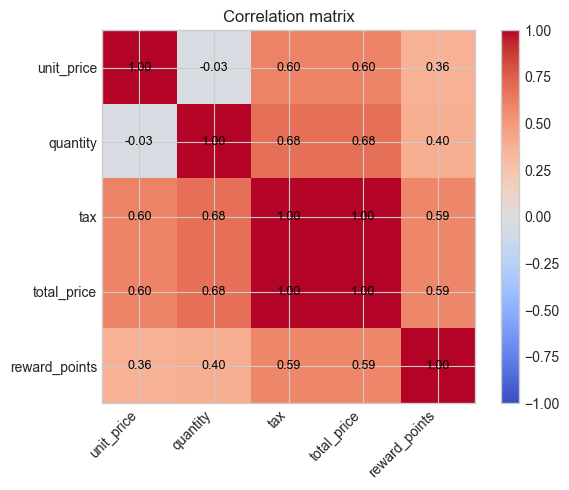

In [7]:
corr_matrix = df[measure_cols].corr(numeric_only=True)
display(corr_matrix.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr_matrix.index)), corr_matrix.index)
for i in range(len(corr_matrix.index)):
    for j in range(len(corr_matrix.columns)):
        ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}', ha='center', va='center', color='black', fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title('Correlation matrix')
plt.tight_layout()
plt.show()

## 7. Top-X значений

In [8]:
top_x = 10
for col in object_cols + ['quantity', 'reward_points']:
    print(f'\nTop {top_x}: {col}')
    display(df[col].value_counts(dropna=False).head(top_x).to_frame('count'))


Top 10: branch


,count
branch,
A,674
B,326



Top 10: city


,count
city,
New York,344
Chicago,330
Los Angeles,326



Top 10: customer_type


,count
customer_type,
Member,516
Normal,484


... (6 outputs left out)


Top 10: quantity


,count
quantity,
2,73
18,58
1,57
19,57
3,53
16,53
20,52
8,52
5,51



Top 10: reward_points


,count
reward_points,
0,507
1,45
2,38
4,36
6,26
3,25
8,22
11,21
5,21


## 8. Гистограммы числовых полей

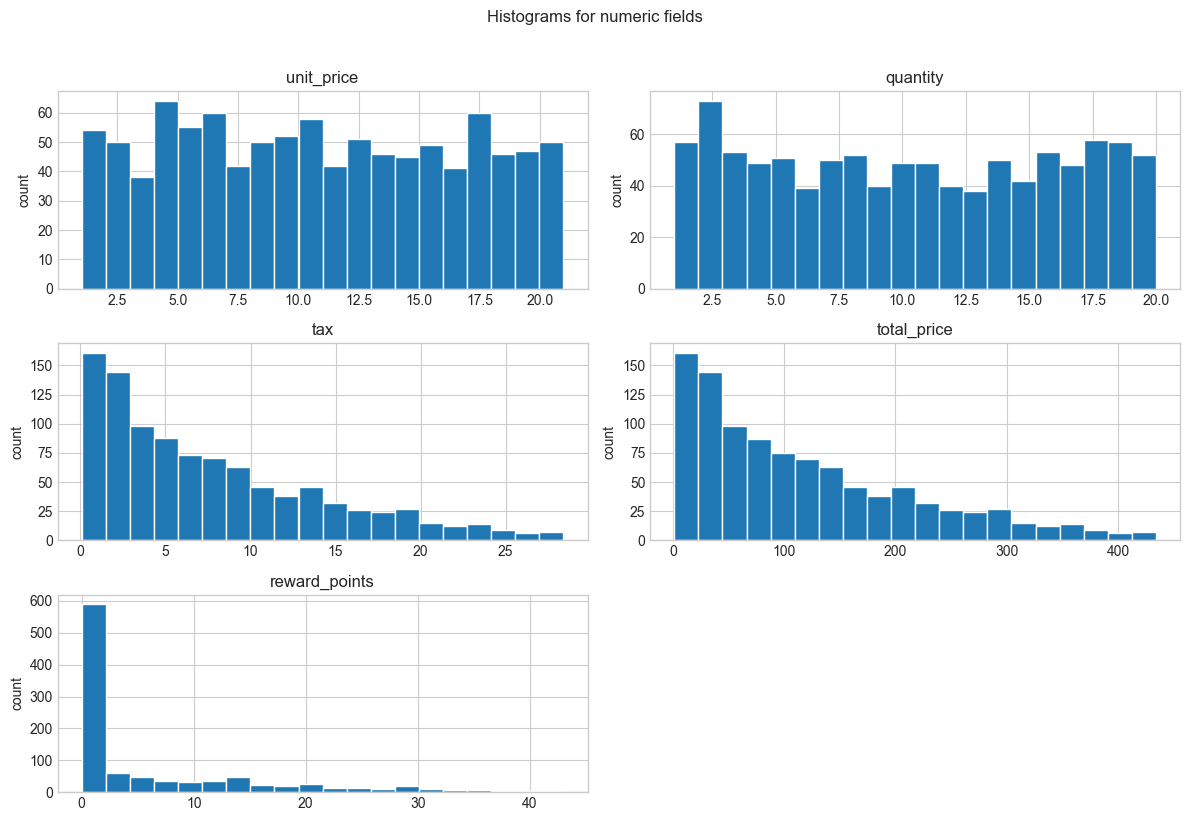

In [9]:
axes = df[measure_cols].hist(bins=20, figsize=(12, 8), edgecolor='white')
for ax in axes.ravel():
    ax.set_ylabel('count')
plt.suptitle('Histograms for numeric fields', y=1.02)
plt.tight_layout()
plt.show()

## 9. Дополнительные sanity-checks

In [10]:
checks = pd.Series({
    'rows': len(df),
    'duplicate_rows': int(df.duplicated().sum()),
    'sale_id_is_unique': bool(df['sale_id'].is_unique),
    'sale_id_nulls': int(df['sale_id'].isna().sum()),
    'invalid_quantity_count': int((df['quantity'] <= 0).sum()),
    'invalid_unit_price_count': int((df['unit_price'] <= 0).sum()),
    'total_price_formula_mismatches': int((~np.isclose(df['total_price'], df['unit_price'] * df['quantity'] + df['tax'], atol=0.01)).sum()),
    'tax_formula_mismatches_7pct': int((~np.isclose(df['tax'], df['unit_price'] * df['quantity'] * 0.07, atol=0.01)).sum()),
    'normal_customer_reward_points_nonzero': int(((df['customer_type'] == 'Normal') & (df['reward_points'] != 0)).sum()),
})
display(checks.to_frame('value'))

,value
rows,1000
duplicate_rows,0
sale_id_is_unique,True
sale_id_nulls,0
invalid_quantity_count,0
invalid_unit_price_count,0
total_price_formula_mismatches,0
tax_formula_mismatches_7pct,0
normal_customer_reward_points_nonzero,0


## 10. Краткие выводы

In [11]:
summary = []
summary.append(f'В наборе {len(df)} строк и {df.shape[1]} столбцов.')
summary.append(f'Пропуски: {int(df.isna().sum().sum())} значений во всем DataFrame.')
summary.append(f'Полных дублей строк: {int(df.duplicated().sum())}. sale_id уникален: {df["sale_id"].is_unique}.')
summary.append(f'Ошибки формулы total_price = unit_price * quantity + tax: {checks["total_price_formula_mismatches"]}.')
summary.append(f'Ошибки формулы tax = 7% от суммы покупки: {checks["tax_formula_mismatches_7pct"]}.')
summary.append('Наиболее сильные ожидаемые корреляции: total_price с tax и quantity; reward_points связан с total_price только для клиентов Member.')
summary.append('PSI рассчитан между первой и второй половинами данных по sale_id; интерпретация дана в таблице PSI.')

for item in summary:
    print('-', item)

- В наборе 1000 строк и 12 столбцов.
- Пропуски: 0 значений во всем DataFrame.
- Полных дублей строк: 0. sale_id уникален: True.
- Ошибки формулы total_price = unit_price * quantity + tax: 0.
- Ошибки формулы tax = 7% от суммы покупки: 0.
- Наиболее сильные ожидаемые корреляции: total_price с tax и quantity; reward_points связан с total_price только для клиентов Member.
- PSI рассчитан между первой и второй половинами данных по sale_id; интерпретация дана в таблице PSI.
